In [1]:
%pip install -q numpy scipy matplotlib qiskit==2.3.1 qiskit-aer==0.17.2


[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [ ]:
# Google Colab: download the project code (evqaoa/, experiments/, results/) if it is not here yet.
import os, sys
if 'google.colab' in sys.modules and not (os.path.isdir('evqaoa') or os.path.isdir('../evqaoa')):
    !git clone -q https://github.com/SakxamShrestha/quant5-fisk-IQ-hackathon
    %cd quant5-fisk-IQ-hackathon/notebooks

In [2]:
import sys, os
# Make the project root (which holds evqaoa/ and experiments/) importable.
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
print('project root found:', os.path.isdir(os.path.join(ROOT, 'evqaoa')))

project root found: True


# 01 - Penalty weights vs. constraint-preserving mixers

**Motivation.** Our depot has 3 vehicles and 4 overnight charging slots, and vehicle *v* must charge in exactly `demand[v]` slots (2, 1, 2). One yes/no choice per vehicle and slot gives 12 qubits, so 2^12 = 4096 bitstrings, but only **144** of them obey every vehicle's demand (3.5 %). A random guess is therefore almost always an invalid schedule. The hackathon's QAOA starter notebook uses a transverse-field (X) mixer, which spreads amplitude over all 4096 bitstrings. We compare two ways of dealing with that:

1. **Penalty term**: add `penalty * (slots charged - slots needed)^2` to the cost so invalid schedules look expensive. How large should the penalty be?
2. **Constraint-preserving XY mixer** (Hadfield et al. 2019; Wang et al. 2020): start from a valid state (a Dicke state, or one fixed valid schedule) and only ever swap a 1 with a neighbouring 0 inside one vehicle's slots, so invalid schedules are never reached.

**Workflow.**
1. Build the depot problem and brute-force the best, worst and average valid schedule.
2. For each configuration and QAOA depth p = 1, 2, 3, tune the angles with COBYLA (warm-started from p-1, exact statevector, no shot noise).
3. **Score every configuration on the same penalty-free objective.** Metrics: *valid rate* (probability of a valid schedule), *P(optimal)* (probability of one of the tied best schedules) and *approximation ratio* (0 = worst valid schedule, 1 = best, measured on the valid part of the distribution).
4. Repeat for 3 random seeds and report mean and spread.

The X-mixer circuits are *optimised* with the penalty included but *scored* without it.

In [3]:
import json, time
import numpy as np
import matplotlib.pyplot as plt
from evqaoa import DEPOT
from experiments.mixer_penalty import (make_study, random_baseline, run_sweep,
                                       summarise, build_configs, WEIGHTS)

PENALTIES = (0, 0.25, 0.5, 1, 2, 5, 10)
SEEDS = (0, 1, 2)
P_MAX, RESTARTS, MAXITER = 3, 3, 300
OUT = os.path.join(ROOT, 'results', '01_mixer_penalty')
os.makedirs(OUT, exist_ok=True)

study = make_study(DEPOT, WEIGHTS)
base = study['baselines']
baseline = random_baseline(DEPOT)
print(f'{DEPOT.n_qubits} qubits, {base.n_valid} valid schedules, {base.n_optimal} tied at the optimum')
print(f'best / mean / worst valid energy: {base.best:.4f} / {base.mean:.4f} / {base.worst:.4f}')
print(f'random-guess valid rate: {baseline:.4f}')

12 qubits, 144 valid schedules, 4 tied at the optimum
best / mean / worst valid energy: 0.5695 / 0.6894 / 0.9250
random-guess valid rate: 0.0352


## Run the ablation
9 configurations x 3 depths x 3 seeds of COBYLA optimisation on 12 qubits.

In [4]:
t0 = time.time()
rows = run_sweep(study, PENALTIES, P_MAX, RESTARTS, MAXITER, SEEDS)
runtime = time.time() - t0
print(f'{len(rows)} optimisation runs in {runtime:.0f} s')

81 optimisation runs in 415 s


In [5]:
vr = summarise(rows, 'valid_rate')
po = summarise(rows, 'p_optimal')
ar = summarise(rows, 'approx_ratio')
names = [c['name'] for c in build_configs(PENALTIES)]
print(f"{'config':<12} p  valid-rate   P(opt)   approx-ratio   (mean over {len(SEEDS)} seeds)")
for n in names:
    for p in range(1, P_MAX + 1):
        print(f"{n:<12} {p}  {vr[(n,p)][0]:9.3f}  {po[(n,p)][0]:7.4f}  {ar[(n,p)][0]:9.3f}")

with open(os.path.join(OUT, 'results.json'), 'w') as f:
    json.dump(dict(weights=WEIGHTS, penalties=PENALTIES, seeds=SEEDS, maxiter=MAXITER,
                   restarts=RESTARTS, random_valid_rate=baseline,
                   E_best=base.best, E_mean=base.mean, E_worst=base.worst,
                   runtime_s=runtime, rows=rows), f, indent=1)

config       p  valid-rate   P(opt)   approx-ratio   (mean over 3 seeds)
X+H pen=0    1      0.001   0.0000      0.592
X+H pen=0    2      0.001   0.0000      0.600
X+H pen=0    3      0.000   0.0000      0.583
X+H pen=0.25 1      0.245   0.0084      0.689
X+H pen=0.25 2      0.269   0.0100      0.701
X+H pen=0.25 3      0.313   0.0125      0.712
X+H pen=0.5  1      0.117   0.0034      0.659
X+H pen=0.5  2      0.331   0.0101      0.672
X+H pen=0.5  3      0.536   0.0163      0.673
X+H pen=1    1      0.206   0.0059      0.663
X+H pen=1    2      0.511   0.0138      0.652
X+H pen=1    3      0.691   0.0185      0.670
X+H pen=2    1      0.238   0.0068      0.664
X+H pen=2    2      0.665   0.0192      0.665
X+H pen=2    3      0.666   0.0192      0.665
X+H pen=5    1      0.175   0.0046      0.655
X+H pen=5    2      0.457   0.0116      0.653
X+H pen=5    3      0.779   0.0177      0.649
X+H pen=10   1      0.236   0.0069      0.669
X+H pen=10   2      0.458   0.0132      0.670
X+H pen

## Plot 1 - Penalty sweep (X mixer + Hadamard start)
Each curve is one depth p; error bars are the standard deviation over seeds. The dotted line is the random-guess valid rate.

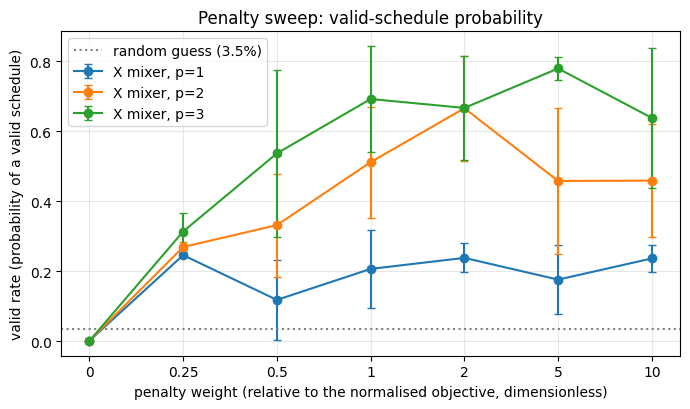

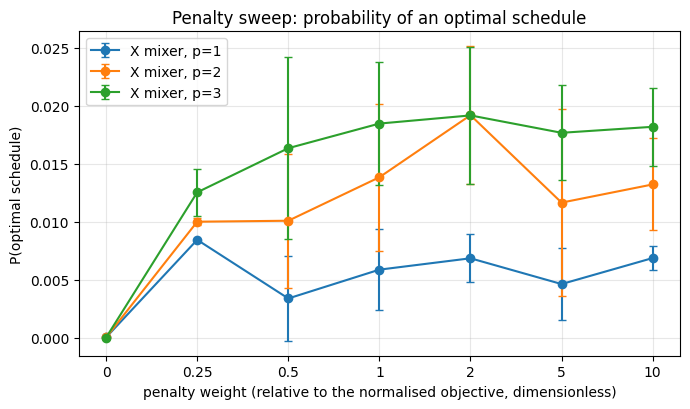

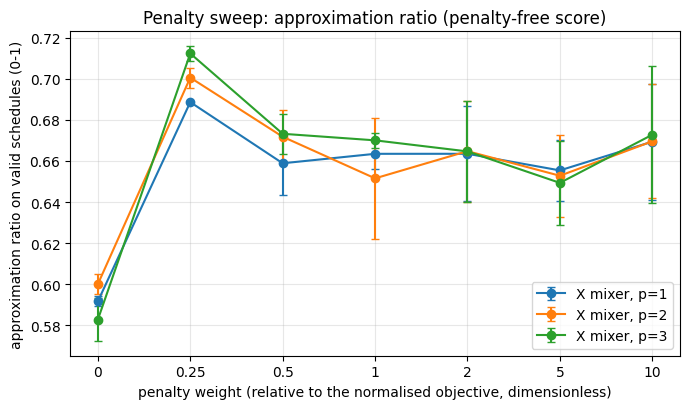

In [6]:
def sweep_plot(summary, ylabel, title, fname, baseline_line=None):
    fig, ax = plt.subplots(figsize=(7, 4.2))
    xs = np.arange(len(PENALTIES))
    for p in range(1, P_MAX + 1):
        m = [summary[(f'X+H pen={pen:g}', p)][0] for pen in PENALTIES]
        s = [summary[(f'X+H pen={pen:g}', p)][1] for pen in PENALTIES]
        ax.errorbar(xs, m, yerr=s, marker='o', capsize=3, label=f'X mixer, p={p}')
    if baseline_line is not None:
        ax.axhline(baseline_line, ls=':', color='gray', label=f'random guess ({baseline_line:.1%})')
    ax.set_xticks(xs); ax.set_xticklabels([f'{q:g}' for q in PENALTIES])
    ax.set_xlabel('penalty weight (relative to the normalised objective, dimensionless)')
    ax.set_ylabel(ylabel); ax.set_title(title); ax.grid(alpha=0.3); ax.legend()
    fig.tight_layout(); fig.savefig(os.path.join(OUT, fname), dpi=150); plt.show()

sweep_plot(vr, 'valid rate (probability of a valid schedule)',
           'Penalty sweep: valid-schedule probability', 'penalty_valid_rate.png', baseline)
sweep_plot(po, 'P(optimal schedule)',
           'Penalty sweep: probability of an optimal schedule', 'penalty_p_optimal.png')
sweep_plot(ar, 'approximation ratio on valid schedules (0-1)',
           'Penalty sweep: approximation ratio (penalty-free score)', 'penalty_approx_ratio.png')

## Plot 2 - Mixer comparison vs. depth p
Best X-mixer penalty (highest mean valid rate at the deepest p) against the two XY variants.

best penalty at p=3 by valid rate: 5


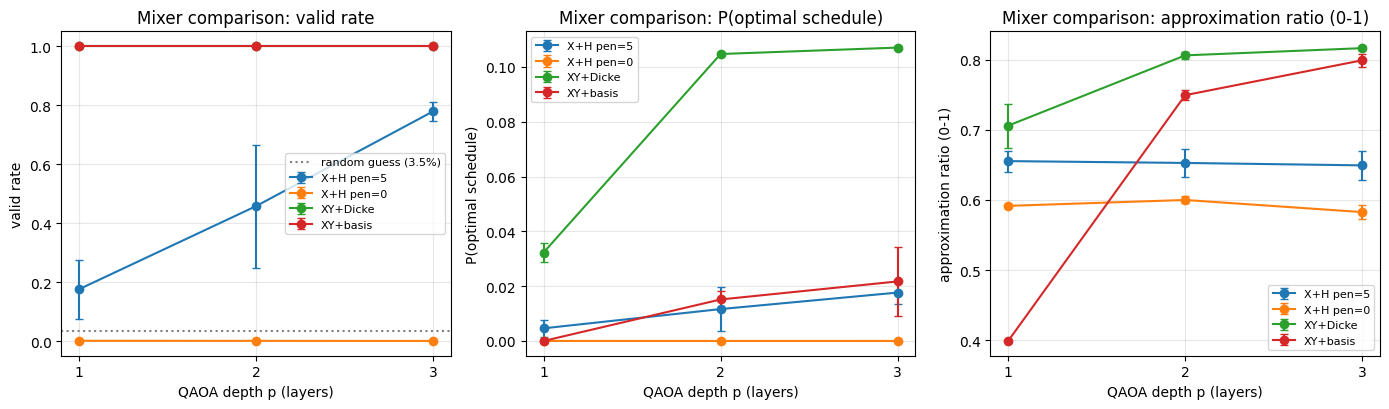

In [7]:
best_pen = max(PENALTIES, key=lambda q: vr[(f'X+H pen={q:g}', P_MAX)][0])
print('best penalty at p=%d by valid rate: %g' % (P_MAX, best_pen))
chosen = [f'X+H pen={best_pen:g}', 'X+H pen=0', 'XY+Dicke', 'XY+basis']
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
specs = [(vr, 'valid rate'), (po, 'P(optimal schedule)'), (ar, 'approximation ratio (0-1)')]
for ax, (summ, label) in zip(axes, specs):
    for n in chosen:
        ps = list(range(1, P_MAX + 1))
        ax.errorbar(ps, [summ[(n, p)][0] for p in ps], yerr=[summ[(n, p)][1] for p in ps],
                    marker='o', capsize=3, label=n)
    if label == 'valid rate':
        ax.axhline(baseline, ls=':', color='gray', label=f'random guess ({baseline:.1%})')
    ax.set_xticks(list(range(1, P_MAX + 1)))
    ax.set_xlabel('QAOA depth p (layers)'); ax.set_ylabel(label)
    ax.set_title(f'Mixer comparison: {label}'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(OUT, 'mixer_comparison.png'), dpi=150); plt.show()

## Plot 3 - Summary at the deepest p
Bars show the mean over seeds with the standard deviation as error bars; the dotted line is the random-guess valid rate.

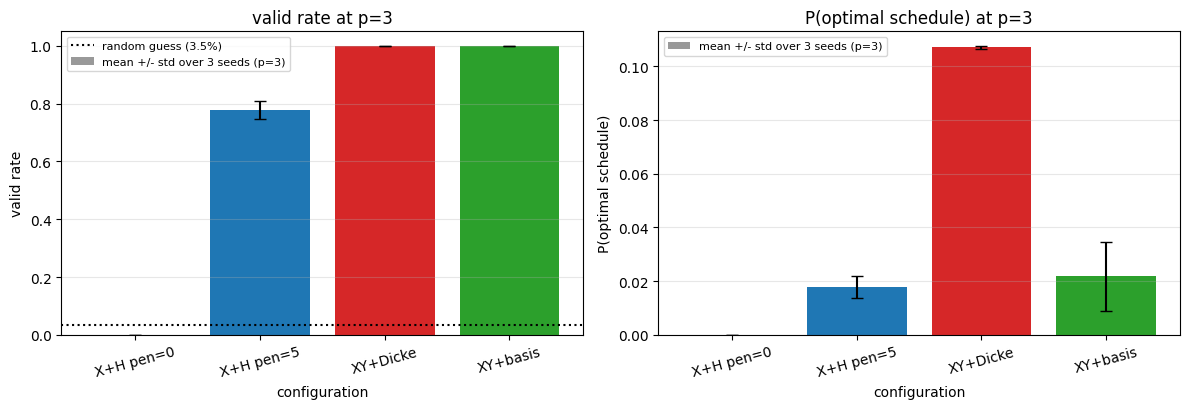

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
labels = ['X+H pen=0', f'X+H pen={best_pen:g}', 'XY+Dicke', 'XY+basis']
for ax, (summ, label) in zip(axes, [(vr, 'valid rate'), (po, 'P(optimal schedule)')]):
    m = [summ[(n, P_MAX)][0] for n in labels]
    s = [summ[(n, P_MAX)][1] for n in labels]
    ax.bar(labels, m, yerr=s, capsize=4, color=['#999999', '#1f77b4', '#d62728', '#2ca02c'],
           label=f'mean +/- std over {len(SEEDS)} seeds (p={P_MAX})')
    if label == 'valid rate':
        ax.axhline(baseline, ls=':', color='k', label=f'random guess ({baseline:.1%})')
    ax.set_xlabel('configuration'); ax.set_ylabel(label)
    ax.set_title(f'{label} at p={P_MAX}'); ax.legend(fontsize=8); ax.grid(axis='y', alpha=0.3)
    ax.tick_params(axis='x', labelrotation=15)
fig.tight_layout(); fig.savefig(os.path.join(OUT, 'summary_bars.png'), dpi=150); plt.show()

In [9]:
# Numbers quoted in the findings below (best seed in brackets), also stored as JSON
summary = {}
for n in names:
    for p in range(1, P_MAX + 1):
        summary[f'{n}|p={p}'] = {k: dict(zip(('mean', 'std', 'best'), s[(n, p)]))
                                 for k, s in (('valid_rate', vr), ('p_optimal', po), ('approx_ratio', ar))}
with open(os.path.join(OUT, 'summary.json'), 'w') as f:
    json.dump(dict(best_penalty=best_pen, summary=summary), f, indent=1)
for n in labels:
    print(f"{n:<12} p={P_MAX}: valid {vr[(n,P_MAX)][0]:.3f} (best {vr[(n,P_MAX)][2]:.3f}), "
          f"P(opt) {po[(n,P_MAX)][0]:.4f} (best {po[(n,P_MAX)][2]:.4f}), "
          f"approx {ar[(n,P_MAX)][0]:.3f} (best {ar[(n,P_MAX)][2]:.3f})")
print('runtime (s):', round(runtime))

X+H pen=0    p=3: valid 0.000 (best 0.000), P(opt) 0.0000 (best 0.0000), approx 0.583 (best 0.595)
X+H pen=5    p=3: valid 0.779 (best 0.824), P(opt) 0.0177 (best 0.0234), approx 0.649 (best 0.676)
XY+Dicke     p=3: valid 1.000 (best 1.000), P(opt) 0.1071 (best 0.1076), approx 0.816 (best 0.820)
XY+basis     p=3: valid 1.000 (best 1.000), P(opt) 0.0217 (best 0.0388), approx 0.799 (best 0.809)
runtime (s): 415


## Findings & limitations

All numbers are means over 3 seeds at p=3 (exact statevector, scored on the penalty-free objective; the run took 415 s). For reference, a random *valid* schedule has approximation ratio 0.663 and is optimal with probability 4/144 = 0.028; a random 12-bit guess is valid 3.5 % of the time.

| configuration | valid rate | P(optimal) | approx. ratio (valid part) |
|---|---|---|---|
| random 12-bit guess | 0.035 | 0.001 | - |
| X + Hadamard, penalty 0 | 0.000 | 0.0000 | 0.583 (almost no valid mass, not meaningful) |
| X + Hadamard, penalty 5 (best valid rate) | 0.779 | 0.0177 | 0.649 |
| X + Hadamard, penalty 2 (best P(optimal) among X) | 0.666 | 0.0192 | 0.665 |
| XY + Dicke | 1.000 | 0.1071 | 0.816 |
| XY + basis | 1.000 | 0.0217 | 0.799 |

**What we saw**
- With no penalty the X mixer ends up almost entirely on invalid schedules (valid rate 0.0002 at p=3): the cost alone favours charging too little.
- Valid rate rises with depth for every nonzero penalty, but the spread across seeds is large. At p=3 it ranges from 0.31 (penalty 0.25) to 0.78 (penalty 5), with standard deviations of 0.15-0.24 for penalties 0.5, 1, 2 and 10. The ordering of penalties 1-10 is therefore not reliable with 3 seeds. Penalty 5 was highest on average and the most consistent (std 0.03).
- Even where the X mixer finds valid schedules, it does not rank them well: P(optimal) is 0.012-0.019 and the approximation ratio is 0.65-0.71, which is no better than picking a valid schedule at random (0.663, and 0.028 for P(optimal)).
- XY + Dicke is 100 % valid by construction and the best on quality: P(optimal) 0.107 (about 4x a random valid guess and 5-6x the best X-mixer result) and approximation ratio 0.816. Almost all of the gain arrives by p=2 (0.105, 0.806).
- XY + basis is also always valid but starts from a single schedule and converges more slowly: at p=1 it is stuck (P(optimal) 0.000, ratio 0.399), then 0.015 / 0.749 at p=2 and 0.022 / 0.799 at p=3. Its approximation ratio approaches Dicke's but its probability of an optimal schedule stays about 5x lower, with a wide seed spread (std 0.013).

**Limitations**
- One 12-qubit instance and one set of objective weights (0.5, 0.3, 0.2); only 3 seeds, 3 restarts and COBYLA with maxiter 300, so differences between penalty values are within noise.
- Ideal statevector simulation: no shot noise and no hardware noise. Dicke state preparation and XY gates are deeper than the X mixer and the basis start, which would matter on real devices.
- The approximation ratio is computed only on the valid part of the distribution, so it is not comparable when the valid rate is near 0 (penalty 0).
- The penalty weight is relative to the normalised objective; other normalisations shift the best weight.
- Four schedules tie at the optimum, so P(optimal) counts all four.